In [2]:
import pandas as pd
df = pd.read_csv("day.csv")
df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
df[["dteday","workingday","casual","registered","cnt"]].head()

,dteday,workingday,casual,registered,cnt
0,2011-01-01,0,331,654,985
1,2011-01-02,0,131,670,801
2,2011-01-03,1,120,1229,1349
3,2011-01-04,1,108,1454,1562
4,2011-01-05,1,82,1518,1600


In [4]:
# Number of rows and columns
print("Dataset shape:", df.shape)

# Missing values in each column
print("\nMissing values")
print(df.isna().sum())

# Number of completely duplicated rows
print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (731, 16)

Missing values
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Duplicate rows: 0


In [5]:
# Convert the date column from text into datetime values
df["dteday"] = pd.to_datetime(df["dteday"])

# Put observations in chronological order
df = df.sort_values("dteday").reset_index(drop=True)

# Check the date range and repeated dates
print("Earliest date:", df["dteday"].min())
print("Latest date:", df["dteday"].max())
print("Repeated dates", df["dteday"].duplicated().sum())

Earliest date: 2011-01-01 00:00:00
Latest date: 2012-12-31 00:00:00
Repeated dates 0


In [6]:
# Training: all of 2011
train = df[
    (df["dteday"] >= "2011-01-01") &
    (df["dteday"] < "2012-01-01")
].copy()

# Validation: January-June 2012
validation = df[
    (df["dteday"] >= "2012-01-01") &
    (df["dteday"] < "2012-07-01")
].copy()

# Test: July-December 2012
test = df[
    (df["dteday"] >= "2012-07-01") &
    (df["dteday"] < "2013-01-01")
].copy()

print("Training rows:", len(train))
print("Validation rows:", len(validation))
print("Test rows:", len(test))

# Check that every row belongs to one of these groups
assert len(train) + len(validation) + len(test) == len(df)

Training rows: 365
Validation rows: 182
Test rows: 184


In [7]:
# Column we will use to predict retal demand
features = [
    "season", "mnth", "weekday", "holiday", "workingday",
    "weathersit", "temp", "hum", "windspeed"
]

# Training inputs and actual rental totals
X_train = train[features].copy()
y_train = train["cnt"].copy()

# Validation inputs and actual rental totals
X_validation = validation[features].copy()
y_validation = validation["cnt"].copy()

# Check their sizes
print("Training inputs:", X_train.shape)
print("training target:", y_train.shape)
print("Validation inputs:", X_validation.shape)
print("Validation target:", y_validation.shape)

X_train.head()

Training inputs: (365, 9)
training target: (365,)
Validation inputs: (182, 9)
Validation target: (182,)


,season,mnth,weekday,holiday,workingday,weathersit,temp,hum,windspeed
0,1,1,6,0,0,2,0.344167,0.805833,0.160446
1,1,1,0,0,0,2,0.363478,0.696087,0.248539
2,1,1,1,0,1,1,0.196364,0.437273,0.248309
3,1,1,2,0,1,1,0.200000,0.590435,0.160296
4,1,1,3,0,1,1,0.226957,0.436957,0.186900


In [8]:
# Learning the average daily rental count from training data only
training_mean = y_train.mean()

print("Training mean:", training_mean)

# Predict that same average for every validation day
baseline_predictions = pd.Series(
    training_mean,
    index=y_validation.index
)

# Compare the first five predictions with the actual counts
comparison = pd.DataFrame({
    "date": validation["dteday"],
    "actual": y_validation,
    "base_line": baseline_predictions
})

comparison.head()

Training mean: 3405.7616438356163


,date,actual,base_line
365,2012-01-01,2294,3405.761644
366,2012-01-02,1951,3405.761644
367,2012-01-03,2236,3405.761644
368,2012-01-04,2368,3405.761644
369,2012-01-05,3272,3405.761644


In [9]:
# Difference between actual and predicted rentals
errors = y_validation - baseline_predictions

# Mean Absolute Erros
baseline_mae = errors.abs().mean()

# Root Mean Squared Error
baseline_rmse = (errors ** 2).mean() ** 0.5

print(f"Baseline MAE: {baseline_mae:.2f} rentals/day")
print(f"Baseline RMSE: {baseline_rmse:.2f} rentals/day")

Baseline MAE: 2052.44 rentals/day
Baseline RMSE: 2449.89 rentals/day


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Category codes, not continuous measurements
categorical_features = [
    "season", "mnth", "weekday", "weathersit"
]

# Measurements and binary indicators
numeric_features = [
    "temp", "hum", "windspeed", "holiday", "workingday"
]

# Encode categories and keep the other inputs unchanged
preprocessor = ColumnTransformer([
    ("categories",
     OneHotEncoder(drop="first", handle_unknown="ignore"),
     categorical_features),

    ("numbers", "passthrough", numeric_features)
])

# Connect preprocessing to linear regression
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regression", LinearRegression())
])

# Learn from training data only
linear_model.fit(X_train, y_train)

print("Linear regression training complete!")

Linear regression training complete!


In [11]:
# Predict rental counts for validation days
linear_predictions = pd.Series(
    linear_model.predict(X_validation),
    index=y_validation.index
)

# Calculate validation errors
linear_errors = y_validation - linear_predictions

linear_mae = linear_errors.abs().mean()
linear_rmse = (linear_errors ** 2).mean() ** 0.5

# Compare with our baseline
results = pd.DataFrame({
    "Model": ["Training-mean baseline", "Linear regression"],
    "Validation MAE": [baseline_mae, linear_mae],
    "Validation RMSE": [baseline_rmse, linear_rmse]
})

results.round(2)

,Model,Validation MAE,Validation RMSE
0,Training-mean baseline,2052.44,2449.89
1,Linear regression,2064.21,2248.70


In [13]:
# Compare both models on the same validation days
error_comparison = pd.DataFrame({
    "date": validation["dteday"],
    "actual": y_validation,
    "baseline_prediction": baseline_predictions,
    "linear_prediction": linear_predictions
})

# Calculate each model's absolute error
error_comparison["baseline_abs_error"] = (
    error_comparison["actual"] - error_comparison["baseline_prediction"]
).abs()

error_comparison["linear_abs_error"] = (
    error_comparison["actual"] - error_comparison["linear_prediction"]
).abs()

# Positive means linear regression made a smaller error
error_comparison["linear_improvement"] = (
    error_comparison["baseline_abs_error"]
    - error_comparison["linear_abs_error"]
)

error_comparison.head(10).round(2)

,date,actual,baseline_prediction,linear_prediction,baseline_abs_error,linear_abs_error,linear_improvement
365,2012-01-01,2294,3405.76,1719.05,1111.76,574.95,536.81
366,2012-01-02,1951,3405.76,1257.02,1454.76,693.98,760.78
367,2012-01-03,2236,3405.76,1159.63,1169.76,1076.37,93.39
368,2012-01-04,2368,3405.76,1089.28,1037.76,1278.72,-240.96
369,2012-01-05,3272,3405.76,1815.00,133.76,1457.00,-1323.23
370,2012-01-06,4098,3405.76,1998.62,692.24,2099.38,-1407.14
371,2012-01-07,4521,3405.76,2176.02,1115.24,2344.98,-1229.74
372,2012-01-08,3425,3405.76,1914.89,19.24,1510.11,-1490.87
373,2012-01-09,2376,3405.76,1253.23,1029.76,1122.77,-93.01
374,2012-01-10,3598,3405.76,1740.38,192.24,1857.62,-1665.38


In [14]:
one_day = pd.DataFrame({
    "date": validation["dteday"],
    "actual": y_validation,
    "baseline_prediction": baseline_predictions,
    "linear_prediction": linear_predictions
})

one_day.head(1).round(2)

,date,actual,baseline_prediction,linear_prediction
365,2012-01-01,2294,3405.76,1719.05


## Initial validation results

Training data: January–December 2011.
Validation data: January–June 2012.
Test data: July–December 2012; not evaluated.

| Model | Validation MAE | Validation RMSE |
|---|---:|---:|
| Training-mean baseline | 2052.44 | 2449.89 |
| Linear regression | 2064.21 | 2248.70 |

Linear regression had slightly worse MAE but lower RMSE.
Since MAE is the primary metric, linear regression did not
outperform the baseline on the primary metric.

Further error analysis is needed before explaining this difference.

In [15]:
print("Average actual rentals:", y_validation.mean())
print("Average predicted rentals:", linear_predictions.mean())
print("Average signed error:", linear_errors.mean())

Average actual rentals: 5152.06043956044
Average predicted rentals: 3104.7552044801223
Average signed error: 2047.305235080318


In [17]:
# January-June 2011: same calendar months as validation
early_2011 = train[
    train["dteday"].dt.month <= 6
]

print(
    "Average rentals, Jan-June 2011:",
    early_2011["cnt"].mean()
)

print(
    "Average rentals, Jan-June 2012:",
    y_validation.mean()
)

Average rentals, Jan-June 2011: 2898.6298342541436
Average rentals, Jan-June 2012: 5152.06043956044


In [19]:
# Average rentals for each month in January-June 2011
monthly_2011 = early_2011.groupby(
    early_2011["dteday"].dt.month
)["cnt"].mean()

# Average rentals for each month in January-June 2012
monthly_2012 = validation.groupby(
    validation["dteday"].dt.month
)["cnt"].mean()

# Put matching months side by side
monthly_comparison = pd.DataFrame({
    "2011 average": monthly_2011,
    "2012 average": monthly_2012
})

monthly_comparison.index.name = "Month"

monthly_comparison.round(2)

,2011 average,2012 average
Month,,
1,1231.90,3120.77
2,1721.96,3556.45
3,2065.97,5318.55
4,3162.33,5807.47
5,4381.32,6318.23
6,4783.73,6761.00


In [20]:
# Use the first training date as a fixed starting point
start_date = train["dteday"].min()

# Calculate elasped days for training and evaluation
train = train.copy()
validation = validation.copy()

train["days_since_start"] = (
    train["dteday"] - start_date
).dt.days

validation["days_since_start"] = (
    validation["dteday"] - start_date
).dt.days

# Check the new values
print(train[["dteday", "days_since_start"]].head())
print(validation[["dteday", "days_since_start"]].head())


      dteday  days_since_start
0 2011-01-01                 0
1 2011-01-02                 1
2 2011-01-03                 2
3 2011-01-04                 3
4 2011-01-05                 4
        dteday  days_since_start
365 2012-01-01               365
366 2012-01-02               366
367 2012-01-03               367
368 2012-01-04               368
369 2012-01-05               369


In [21]:
# Original nine features, plus elapsed days
trend_features = features + ["days_since_start"]

# Create separate inputs for our new experiment
X_train_trend = train[trend_features].copy()
X_validation_trend = validation[trend_features].copy()

# Check the sizes
print("Training inputs with time:", X_train_trend.shape)
print("Validation inputs with time:", X_validation_trend.shape)

X_train_trend.head()

Training inputs with time: (365, 10)
Validation inputs with time: (182, 10)


,season,mnth,weekday,holiday,workingday,weathersit,temp,hum,windspeed,days_since_start
0,1,1,6,0,0,2,0.344167,0.805833,0.160446,0
1,1,1,0,0,0,2,0.363478,0.696087,0.248539,1
2,1,1,1,0,1,1,0.196364,0.437273,0.248309,2
3,1,1,2,0,1,1,0.200000,0.590435,0.160296,3
4,1,1,3,0,1,1,0.226957,0.436957,0.186900,4


In [22]:
# Add elapsed time to the numerical columns
numeric_features_trend = numeric_features + ["days_since_start"]

# Create a NEW preprocessor
preprocessor_trend = ColumnTransformer([
    (
        "categories",
        OneHotEncoder(drop="first", handle_unknown="ignore"),
        categorical_features
    ),
    (
        "numbers",
        "passthrough",
        numeric_features_trend
    )
])

# Create a NEW model, preserving the original linear_model
trend_model = Pipeline([
    ("preprocessor", preprocessor_trend),
    ("regression", LinearRegression())
])

# Train using 2011 data only
trend_model.fit(X_train_trend, y_train)

print("Regression with elapsed time trained!")

Regression with elapsed time trained!


In [23]:
# Predict using the model with elapsed time
trend_predictions = pd.Series(
    trend_model.predict(X_validation_trend),
    index=y_validation.index
)

# Calculate errors
trend_errors = y_validation - trend_predictions

trend_mae = trend_errors.abs().mean()
trend_rmse = (trend_errors ** 2).mean() ** 0.5

# Compare all three approaches
trend_results = pd.DataFrame({
    "Model": [
        "Mean baseline",
        "Original linear regression",
        "Linear regression with time"
    ],
    "Validation MAE": [
        baseline_mae, linear_mae, trend_mae
    ],
    "Validation RMSE": [
        baseline_rmse, linear_rmse, trend_rmse
    ]
})

trend_results.round(2)

,Model,Validation MAE,Validation RMSE
0,Mean baseline,2052.44,2449.89
1,Original linear regression,2064.21,2248.70
2,Linear regression with time,3583.13,3701.48


In [24]:
print(f"Actual average: {y_validation.mean():.2f}")
print(f"Time-model prediction average: {trend_predictions.mean():.2f}")
print(f"Time-model signed error: {trend_errors.mean():.2f}")

Actual average: 5152.06
Time-model prediction average: 1568.93
Time-model signed error: 3583.13


In [25]:
# Names of the prepared input columns
feature_names = (
    trend_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Coefficient learned for each prepared column
coefficients = pd.Series(
    trend_model.named_steps["regression"].coef_,
    index=feature_names
)

# Display the coefficient for elapsed time
print(coefficients[
    coefficients.index.str.contains("days_since_start")
])

numbers__days_since_start   -4.206015
dtype: float64


Adding elapsed days worsened validation MAE from 2,064.21 to 3,583.13 rentals/day. The model learned a time coefficient of −4.206, contributing to increased underprediction. With only one training year and overlapping calendar features, this coefficient should not be interpreted as long-term demand growth.

In [26]:
# Predict the training days using the time model
trend_train_predictions = pd.Series(
    trend_model.predict(X_train_trend),
    index=y_train.index
)

# Calculate average absolute error on training data
trend_train_mae = (
    y_train - trend_train_predictions
).abs().mean()

print(f"Time-model training MAE: {trend_train_mae:.2f}")
print(f"Time-model validation MAE: {trend_mae:.2f}")

Time-model training MAE: 406.74
Time-model validation MAE: 3583.13


## Experiment: adding elapsed time

The model was trained on 2011 and evaluated on January–June 2012.

- Training MAE: 406.74 rentals/day.
- Validation MAE: 3583.13 rentals/day.
- Original regression validation MAE: 2064.21 rentals/day.
- Mean-baseline validation MAE: 2052.44 rentals/day.
- Learned elapsed-time coefficient: approximately -4.206.

Adding elapsed time worsened validation performance.
The large training–validation gap indicates poor generalization
to the later period.

Demand increased across all six matched months, but the fitted
time effect was negative. A single training year with overlapping
calendar features may not reliably separate growth from seasonality.

The time-based model is not selected. Final test data remains unused.

In [28]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor

# Create a separate workflow using the original preprocessing
forest_model = Pipeline([
    ("preprocessor", clone(linear_model.named_steps["preprocessor"])),
    ("regression", RandomForestRegressor(
        n_estimators=300,
        max_depth=10,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

# Train on the original nine features—not X_train_trend
forest_model.fit(X_train, y_train)

print("Random forest training complete!")

Random forest training complete!


In [29]:
# Predict validation rental counts
forest_predictions = pd.Series(
    forest_model.predict(X_validation),
    index=y_validation.index
)

# Calculate prediction errors
forest_errors = y_validation - forest_predictions

forest_mae = forest_errors.abs().mean()
forest_rmse = (forest_errors ** 2).mean() ** 0.5

# Compare all experiments
all_results = pd.DataFrame({
    "Model": [
        "Mean baseline",
        "Original linear regression",
        "Linear regression with time",
        "Random forest"
    ],
    "Validation MAE": [
        baseline_mae, linear_mae, trend_mae, forest_mae
    ],
    "Validation RMSE": [
        baseline_rmse, linear_rmse, trend_rmse, forest_rmse
    ]
})

all_results.round(2)

,Model,Validation MAE,Validation RMSE
0,Mean baseline,2052.44,2449.89
1,Original linear regression,2064.21,2248.70
2,Linear regression with time,3583.13,3701.48
3,Random forest,1925.90,2091.11


In [30]:
# Put predictions beside the actual rental counts
forest_review = pd.DataFrame({
    "date": validation["dteday"],
    "actual": y_validation,
    "predicted": forest_predictions
})

# Positive error means underprediction
forest_review["error"] = (
    forest_review["actual"] - forest_review["predicted"]
)

forest_review["absolute_error"] = forest_review["error"].abs()

# Show the five days with the largest mistakes
forest_review.nlargest(5, "absolute_error").round(2)

,date,actual,predicted,error,absolute_error
461,2012-04-06,6460,2255.25,4204.75,4204.75
462,2012-04-07,6857,2752.97,4104.03,4104.03
455,2012-03-31,6235,2390.54,3844.46,3844.46
447,2012-03-23,8362,4544.13,3817.87,3817.87
460,2012-04-05,6457,2843.20,3613.80,3613.80


In [31]:
print(f"Average signed error: {forest_errors.mean():.2f}")

underprediction_percent = (forest_errors > 0).mean() * 100

print(
    f"Percentage of days underpredicted: "
    f"{underprediction_percent:.1f}%"
)

Average signed error: 1902.01
Percentage of days underpredicted: 97.8%


## Random forest validation findings

- Validation MAE: 1925.90 rentals/day.
- Validation RMSE: 2091.11 rentals/day.
- MAE improved by approximately 6.2% over the mean baseline.
- Average signed error: +1902.01 rentals/day.
- Underprediction occurred on 97.8% of validation days.
- The five largest absolute errors occurred in March and April 2012
  and were all underpredictions.

The forest is the best model tested so far on validation MAE,
but substantial systematic underprediction remains.

Higher demand in 2012 may contribute to this weakness;
the analysis does not establish its cause.

Final test data remains unused.

## Final model selection

Random forest was selected because it achieved the lowest
validation MAE among the four approaches tested: 1925.90 rentals/day.

Its original nine features and hyperparameters are now fixed.
It will be refitted on January 2011–June 2012, then evaluated
on the reserved July–December 2012 test period.

No changes will be made based on final test scores.

In [32]:
from sklearn.base import clone

# Combine training and validation into one development dataset
development = pd.concat(
    [train, validation]
).sort_values("dteday")

# Use the original nine features, without elapsed time
X_development = development[features].copy()
y_development = development["cnt"].copy()

# Create a fresh model with the same settings
final_model = clone(forest_model)

# Refit preprocessing and regression using development data only
final_model.fit(X_development, y_development)

print("Development rows:", len(development))
print("Final random forest trained!")

Development rows: 547
Final random forest trained!


In [33]:
# Prepare test inputs and actual rental counts
X_test = test[features].copy()
y_test = test["cnt"].copy()

# Check that development comes before test
assert development["dteday"].max() < test["dteday"].min()

# Predict with the fixed final model
final_predictions = pd.Series(
    final_model.predict(X_test),
    index=y_test.index
)

# Baseline: development-set average, not test-set average
test_baseline_predictions = pd.Series(
    y_development.mean(),
    index=y_test.index
)

# Calculate both models' test errors
final_errors = y_test - final_predictions
test_baseline_errors = y_test - test_baseline_predictions

# Display final test metrics
test_results = pd.DataFrame({
    "Model": ["Development-mean baseline", "Final random forest"],
    "Test MAE": [
        test_baseline_errors.abs().mean(),
        final_errors.abs().mean()
    ],
    "Test RMSE": [
        (test_baseline_errors ** 2).mean() ** 0.5,
        (final_errors ** 2).mean() ** 0.5
    ]
})

test_results.round(2)

,Model,Test MAE,Test RMSE
0,Development-mean baseline,2452.64,2694.30
1,Final random forest,2115.43,2256.88


## Final test evaluation

Random forest was selected using validation MAE, then refitted
on January 2011–June 2012 without changing its settings.

Final evaluation used 184 held-out days from July–December 2012.

| Model | Test MAE | Test RMSE |
|---|---:|---:|
| Development-mean baseline | 2452.64 | 2694.30 |
| Final random forest | 2115.43 | 2256.88 |

The random forest reduced test MAE by approximately 13.7%
and test RMSE by 16.2% relative to the development-mean baseline.

Substantial prediction error remains. The project uses historical
data and observed same-day weather, so it does not demonstrate
a deployable advance-forecasting system.

Test results will not be used to tune this model.

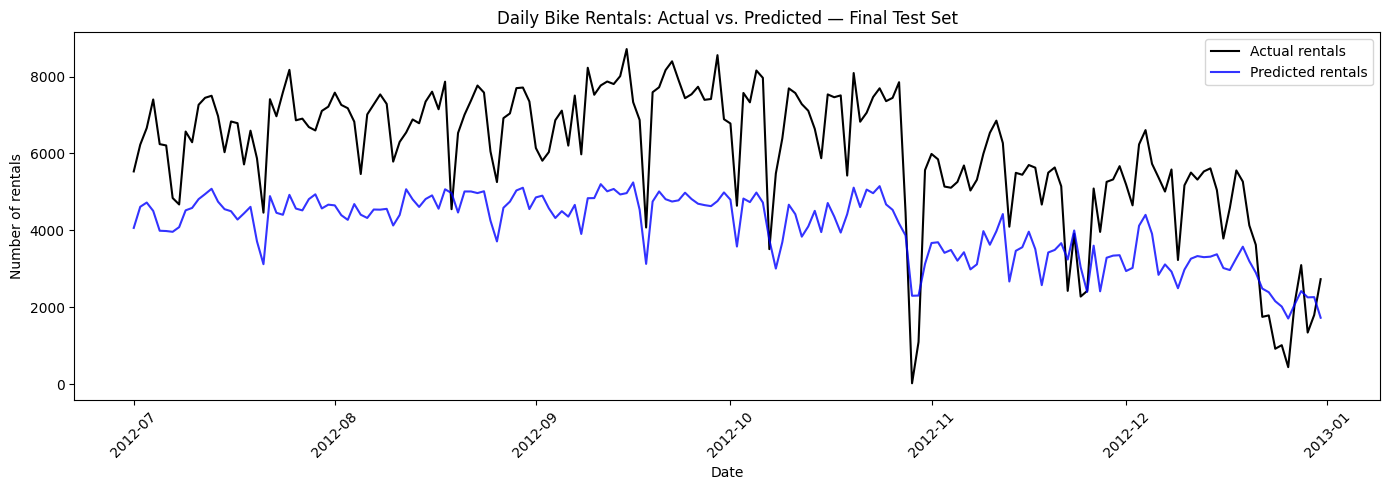

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    test["dteday"],
    y_test,
    label="Actual rentals",
    color="black"
)

plt.plot(
    test["dteday"],
    final_predictions,
    label="Predicted rentals",
    color="blue",
    alpha=0.8
)

plt.title("Daily Bike Rentals: Actual vs. Predicted — Final Test Set")
plt.xlabel("Date")
plt.ylabel("Number of rentals")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()